In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from scipy.optimize import least_squares
from scipy.special import modstruve
from scipy.special import kv
from scipy.io import loadmat
from scipy.stats import norm
from scipy.stats import t

In [2]:
# First part of the model.
def func(y, a, λ):
    b = (y-a)/λ
    c = (y+a)/λ
    return c*modstruve(-1,c)*kv(0,c) + c*modstruve(0,c)*kv(1,c) - b*modstruve(-1,b)*kv(0,b) - b*modstruve(0,b)*kv(1,b)

# Define the full model function.
def model_func(params, y, a):
    λ = params[0]
    C = params[1]
    return C*func(y, a, λ)

# Define the residuals function for multiple energies.
def residuals(params, I, y, a):
    return I - model_func(params, y, a)

''' Suggested by ChatGPT '''
def model_confidence_band(params, covariance, dof, y, a, confidence_level=0.95):
    # Evaluate the fitted curve.
    model_A = np.asarray(model_func(params, y, a)).ravel()

    # Calculate the gradient with respect to λ and C.
    G = np.empty((model_A.size, 2))

    # Numerical derivative with respect to λ.
    h = np.cbrt(np.finfo(float).eps)*max(abs(params[0]), 1.0)
    p_plus, p_minus = params.copy(), params.copy()
    p_plus[0] += h
    p_minus[0] -= h

    G[:,0] = ((model_func(p_plus, y, a) -
               model_func(p_minus, y, a))/(2*h)).ravel()

    # Analytical derivative with respect to C.
    G[:,1] = np.asarray(func(y, a, params[0])).ravel()

    # Propagate parameter covariance to the fitted curve.
    variance = np.einsum('ij,jk,ik->i', G, covariance, G)
    sigma = np.sqrt(np.maximum(variance, 0))

    # Calculate pointwise 95% confidence limits.
    t_crit = t.ppf(1-(1-confidence_level)/2, dof)

    model_A_lower = model_A - t_crit*sigma
    model_A_upper = model_A + t_crit*sigma

    return model_A, model_A_lower, model_A_upper

In [3]:
# Load data.
dataset = loadmat('Light_Collecting_Intensity_Data_updated_error_bars.mat')
energies = dataset['energies'] # Energies in eV.
slit_separations = dataset['slit_separations'] # Slit separations in mm.
positions = dataset['positions'] # Positions in µm.
intensities = dataset['intensities'] # Intensities (unitless).
intensity_errors = dataset['intensity_errors'] # Intensity standard deviations (unitless).

In [4]:
# Dimensions (for reshaping arrays).
dims = np.shape(intensities) # The dimensions correspond to energy, slit separation, and position.
n_E = dims[0]
n_a = dims[1]
n_y = dims[2]

# Reshape arrays (only to be flattened).
# Energy.
E_expanded = np.reshape(energies, (n_E, 1, 1))  # Reshape to (n_E, 1, 1).
E = np.broadcast_to(E_expanded, (n_E, n_a, n_y))  # Broadcast to (n_E, n_r, n_d).
# Half slit separation.
a_expanded = np.reshape(slit_separations/2, (1, n_a, 1))
a = np.broadcast_to(a_expanded, (n_E, n_a, n_y))

# We'll assign all patterns a global average y-value.
y = positions
y_avg = np.mean(y)
y_std = np.std(y)

# Normalize the data.
I = intensities/np.max(intensities)

scale_bar = 0.4528

# Rescale: everything should be in units of mm.
y_avg = y_avg*scale_bar/1e3 # Converting pixels to mm.
y_std = y_std*scale_bar/1e3

# Rescale: energy should be in units of keV.
E = E/1e3 # Converting eV to keV.

In [5]:
''' Fit the data. '''
'''    i    || 0 | 1  | 2  | 3  | 4  | 5  | 6  ||
    --------||---------------------------------||
    E [keV] || 8 | 11 | 14 | 17 | 20 | 23 | 25 ||
'''
n_params = 2
parameter_estimates = np.zeros((n_E, n_params))
parameter_errors = np.zeros((n_E, n_params))
unique_E_vals = np.unique(E)
covariance_matrices = np.zeros((n_E, n_params, n_params))
fit_dofs = np.zeros(n_E, dtype=int)
for i, E_val in enumerate(unique_E_vals):  # Loop through unique E-values.
    # We are going to collapse the data by assigning to all patterns average I-values.
#     I_avg = np.squeeze(np.mean(I[i,:,:], axis=1, keepdims=True))
    I_avg = np.squeeze(I[i,:,:]) # Don't average.

    # Collapse the energy and slit separation data.
#     E_collapsed = np.squeeze(E[i,:,0])
#     a_collapsed = np.squeeze(a[i,:,0])
    E_collapsed = np.squeeze(E[i,:,:])
    a_collapsed = np.squeeze(a[i,:,:])
    
    # Flatten arrays.
    E_flat = E_collapsed.flatten() # E = energy.
    a_flat = a_collapsed.flatten() # a = half slit separation.
    I_flat = I_avg.flatten() # I = intensity.

    # Initial guesses.
    wvl = 1030e-9/1e-3 # In mm.
    k = 1e-6
    λ_init = wvl/(4*np.pi*k) # Initial guess is attenuation length from Beer-Lambert law.
    C_init = 1.0
    initial_params = np.hstack([λ_init, C_init])

    # Perform the fit.
    result = least_squares(residuals, initial_params, args=(I_flat, y_avg, a_flat))
    
    # Extract fitted parameters.
    parameter_estimates[i,:] = result.x
    
    # Calculate the Jacobian matrix and the cost.
    J = result.jac # Jacobian matrix at the solution.
    cost = result.cost # Sum of squared residuals at the solution.
    degrees_of_freedom = len(I_flat) - 2 # Number of data points minus number of parameters.

    # Estimate the variance of the residuals.
    residual_variance = cost/degrees_of_freedom

    # Calculate the covariance matrix for the parameters.
    covariance_matrix = residual_variance*np.linalg.inv(J.T @ J)

    # Calculate the standard errors (square roots of the diagonal of the covariance matrix).
    parameter_errors[i,:] = np.sqrt(np.diag(covariance_matrix))

In [6]:
# confidence_level = 0.95
# z = norm.ppf(1-(1-confidence_level)/2)  # 1.96 for 95% confidence.

# Calculate upper and lower bounds for each parameter.
# result_upper = parameter_estimates + z*parameter_errors
# result_lower = parameter_estimates - z*parameter_errors

In [7]:
np.where(unique_E_vals==E_val)[0][0]

6

meta NOT subset; don't know how to subset; dropped


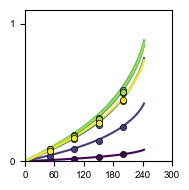

In [8]:
# Set font globally.
plt.rcParams['pdf.fonttype'] = 42  # Type 42 (TrueType), required for Adobe Illustrator.
plt.rcParams['ps.fonttype'] = 42   # Ensures fonts are saved as TrueType in EPS.
plt.rcParams['font.family'] = 'Arial'
params = {'mathtext.default': 'regular' }          
plt.rcParams.update(params)

# Create a grid of subplots with one subplot per unique a-value.
fig, ax = plt.subplots(1, 1, figsize=(2,2), sharex=True, sharey=True)

# Set up a colormap for the E-values.
plot_E_vals = np.array([8., 11., 14., 17., 20., 23., 25.]) # All E-values: 8, 11, 14, 17, 20, 23, 25 [keV].
norm = plt.Normalize(vmin=np.min(plot_E_vals), vmax=np.max(plot_E_vals))
cmap = cm.viridis
colors = cmap(norm(plot_E_vals))  # Map E-values to colors.

# Loop over each unique E-value.
unique_E_vals = np.unique(E)
for i, E_val in enumerate(plot_E_vals):
    idx = np.where(unique_E_vals==E_val)[0][0]
    
    # See here for calculation of mean and error:
    # https://physics.stackexchange.com/questions/679853/how-to-calculate-the-uncertainty-and-mean-of-multiple-measurements-with-differen
    I_avg = np.sum(I[idx,:,:]/(intensity_errors[idx,:,:]**2),axis=1)/np.sum(1/(intensity_errors[idx,:,:]**2),axis=1)
    I_err = 1/np.sqrt(np.sum(1/(intensity_errors[idx,:,:]**2),axis=1))
    
    E_collapsed = np.squeeze(E[idx,:,0])
    a_collapsed = np.squeeze(a[idx,:,0])
    
    # Get the indices for the current a-value.
    mask = E_collapsed == E_val
    # Use the mask to filter.
    a_filtered = a_collapsed[mask]
    I_filtered = I_avg[mask]
    
    # Plot the model fit.
#     y_fit = y_avg
#     a_fit = np.arange(0.0, 0.3+0.001, 0.001)
#     model_I = model_func(parameter_estimates[idx,:], y_fit, a_fit)
#     model_I_lower = model_func(result_lower[idx,:], y_avg, a_fit)
#     model_I_upper = model_func(result_upper[idx,:], y_avg, a_fit)
#     plt.plot(a_fit*1e3, model_I, color=colors[i])
#     plt.fill_between(a_fit*1e3, model_I_upper, model_I_lower, color=colors[i], alpha=0.25)
    y_fit = y_avg
    a_fit = np.arange(0.0, 0.3+0.001, 0.001)
    model_I, model_I_lower, model_I_upper = model_confidence_band(
        parameter_estimates[idx,:],
        covariance_matrices[idx,:,:],
        fit_dofs[idx],
        y_fit,
        a_fit
    )
    ax.plot(a_fit*1e3, model_I, color=colors[i])
    ax.fill_between(a_fit*1e3, model_I_lower, model_I_upper, color=colors[i], alpha=0.25)
    
    # Plot the raw data.
#     ax.errorbar(
#     a_filtered*1e3, I_filtered,
#     yerr=I_err[mask]/np.max(intensities), # Vertical error bars. Remember to normalize!
#     marker='o', mec='black', markersize=4, color=colors[i], ecolor='black', capsize=2.0, linestyle='', label=f"{E_val:.0f}"
#     )
    ax.errorbar(a_filtered*1e3, I_filtered,
                yerr=I_err[mask]/np.max(intensities),
                fmt='none',
                ecolor=colors[i],
                capsize=0)
    ax.scatter(a_filtered*1e3, I_filtered, 20,
               facecolor=colors[i], linewidths=0.5, edgecolor='black', zorder=10,
               label='{:.1f} keV'.format(E_val))
    
# Axis labels.
# ax.set_xlabel('a [µm]', fontsize=7)
# ax.set_xlabel(None)
# ax.set_ylabel('Intensity (a.u.)', fontsize=7)
# ax.set_ylabel(None)
plt.xticks(fontsize=7)
plt.yticks(fontsize=7)
ax.set_xlim([0, 300])
ax.set_ylim([0, 1.1])
ax.set_xticks([0, 60, 120, 180, 240, 300])
ax.set_yticks([0, 1])
# Legend.
# ax.legend(loc="upper left",  fontsize=7, title="E (keV)",
#           title_fontsize='small', frameon=True, facecolor='white', edgecolor='black')

# Adjust the size of the figure.
plt.tight_layout()
width, height = fig.get_size_inches()
aspect_ratio = 1
new_height = 2
new_width = new_height*aspect_ratio
fig.set_size_inches(new_width, new_height)

# Save with font embedded.
# plt.savefig("data_fit_thesis.pdf", format="pdf", bbox_inches='tight')
# plt.savefig("data_fit.eps", format="eps", bbox_inches='tight')
# plt.savefig("data_fit_CLEO_slides.png", format="png", bbox_inches='tight')

# plt.savefig("fig_3_yagyb_synchrotron.pdf", format="pdf", bbox_inches='tight')
plt.savefig("fig_3_yagyb_synchrotron_10-19-2026.pdf", format="pdf", bbox_inches='tight')

plt.show()

In [9]:
# parameter_estimates_µm = parameter_estimates
# parameter_estimates_µm[:,0] = parameter_estimates_µm[:,0]*1e3
# parameter_errors_µm = parameter_errors
# parameter_errors_µm[:,0] = parameter_errors_µm[:,0]*1e3

In [10]:
''' Correction (?) suggested by ChatGPT '''
parameter_estimates_µm = parameter_estimates.copy()
parameter_estimates_µm[:,0] *= 1e3

parameter_errors_µm = parameter_errors.copy()
parameter_errors_µm[:,0] *= 1e3

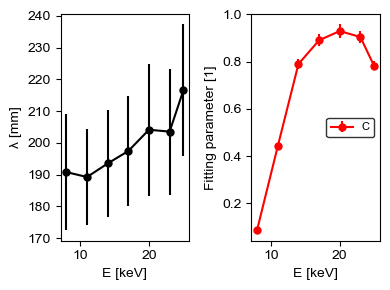

In [11]:
# Plot parameter estimates as a function of energy (with error bars).
fig, axes = plt.subplots(1, 2, sharex=True)

# Plot λ...
ax = axes[0]
ax.errorbar(
    unique_E_vals, parameter_estimates_µm[:,0],
    yerr=parameter_errors_µm[:,0], # Vertical error bars
    marker='o', color='black', markersize=5
    )
ax.set_xlabel('E [keV]')
ax.set_ylabel('λ [mm]')

# Plot C and D...
ax = axes[1]
ax.errorbar(
    unique_E_vals, parameter_estimates_µm[:,1],
    yerr=parameter_errors_µm[:,1], # Vertical error bars
    marker='o', color='red', markersize=5, label='C'
    )
ax.set_xlabel('E [keV]')
ax.set_ylabel('Fitting parameter [1]')
ax.legend(loc="center right",  fontsize=8, title_fontsize='small', frameon=True, facecolor='white', edgecolor='black')

# Adjust the size of the figure.
plt.tight_layout()
width, height = fig.get_size_inches()
aspect_ratio = 4/3
new_height = 3
new_width = new_height*aspect_ratio
fig.set_size_inches(new_width, new_height)

plt.tight_layout()
plt.show()

In [12]:
# Save fitting parameters.
# np.savez('fitting_parameters_yagyb_synchrotron.npz', parameter_estimates_µm, parameter_errors_µm, unique_E_vals)
np.savez('fitting_parameters_yagyb_synchrotron_10-19-2026.npz', parameter_estimates_µm, parameter_errors_µm, unique_E_vals)